In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
# data visualixxaton
import matplotlib.pyplot as plt
import seaborn as sns
#models ml tools 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [2]:
print(tf.__version__)
import tensorflow as tf
print(tf.__version__)
print(tf.test.is_built_with_cuda())       # Should be True
print(tf.config.list_physical_devices('GPU'))  # Should list your GPU

\
print("Built with CUDA:",tf.config.list_physical_devices('GPU'))
print("GPU available:", tf.test.is_gpu_available())




2.20.0
2.20.0
False
[]
Built with CUDA: []
Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.
GPU available: False


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("GPUs:", tf.config.list_physical_devices('GPU'))

model = keras.Sequential([
    layers.Dense(128, activation='relu'),
    layers.Dense(10)
])

model.compile(optimizer='adam', loss='mse')
import numpy as np
x = np.random.rand(1000, 20)
y = np.random.rand(1000, 10)

model.fit(x, y, epochs=5)


GPUs: []
Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2150   
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1000 
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0941 
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0912 
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0892 


In [4]:
BATCH_SIZE = 120
IMAGE_SIZE = 256
CHANNELS=3
EPOCHS=50

In [5]:
dataDir = tf.keras.preprocessing.image_dataset_from_directory(
    r"C:\Users\YASHASH RAVI\Downloads\plantimages\PlantVillage",
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

print(dataDir)

# column name
column_name = dataDir.class_names
print(np.array(column_name))


Found 32681 files belonging to 15 classes.
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
['Pepper__bell___Bacterial_spot' 'Pepper__bell___healthy'
 'Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy'
 'Tomato_Bacterial_spot' 'Tomato_Early_blight' 'Tomato_Late_blight'
 'Tomato_Leaf_Mold' 'Tomato_Septoria_leaf_spot'
 'Tomato_Spider_mites_Two_spotted_spider_mite' 'Tomato__Target_Spot'
 'Tomato__Tomato_YellowLeaf__Curl_Virus' 'Tomato__Tomato_mosaic_virus'
 'Tomato_healthy']


In [6]:
import os

# handling imabalance datasets
data_dir = r"C:\Users\YASHASH RAVI\Downloads\plantimages\PlantVillage"
class_counts = {}

for cls in os.listdir(data_dir):
    cls_path = os.path.join(data_dir, cls)
    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

print(np.array(class_counts))


{'Pepper__bell___Bacterial_spot': 1994, 'Pepper__bell___healthy': 1970, 'Potato___Early_blight': 2000, 'Potato___healthy': 2280, 'Potato___Late_blight': 2000, 'Tomato_Bacterial_spot': 2128, 'Tomato_Early_blight': 2000, 'Tomato_healthy': 2051, 'Tomato_Late_blight': 1969, 'Tomato_Leaf_Mold': 1904, 'Tomato_Septoria_leaf_spot': 2743, 'Tomato_Spider_mites_Two_spotted_spider_mite': 2021, 'Tomato__Target_Spot': 2174, 'Tomato__Tomato_mosaic_virus': 2238, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 3210}


In [ ]:
# {
#     "Pepper__bell___Bacterial_spot": 997,
#     "Pepper__bell___healthy": 1478,
#     "Potato___Early_blight": 1000,
#     "Potato___healthy": 152,
#     "Potato___Late_blight": 1000,
#     "Tomato_Bacterial_spot": 2127,
#     "Tomato_Early_blight": 1000,
#     "Tomato_healthy": 1591,
#     "Tomato_Late_blight": 1909,
#     "Tomato_Leaf_Mold": 952,
#     "Tomato_Septoria_leaf_spot": 1771,
#     "Tomato_Spider_mites_Two_spotted_spider_mite": 1676,
#     "Tomato__Target_Spot": 1404,
#     "Tomato__Tomato_mosaic_virus": 373,
#     "Tomato__Tomato_YellowLeaf__Curl_Virus": 3209,
# }

In [7]:
column_data = {
    "Pepper__bell___Bacterial_spot": 0,
    "Pepper__bell___healthy": 1,
    "Potato___Early_blight": 2,
    "Potato___healthy": 3,
    "Potato___Late_blight": 4,
    "Tomato_Bacterial_spot": 5,
    "Tomato_Early_blight": 6,
    "Tomato_healthy": 7,
    "Tomato_Late_blight": 8,
    "Tomato_Leaf_Mold": 9,
    "Tomato_Septoria_leaf_spot": 10,
    "Tomato_Spider_mites_Two_spotted_spider_mite": 11,
    "Tomato__Target_Spot": 12,
    "Tomato__Tomato_mosaic_virus": 13,
    "Tomato__Tomato_YellowLeaf__Curl_Virus": 14,
}

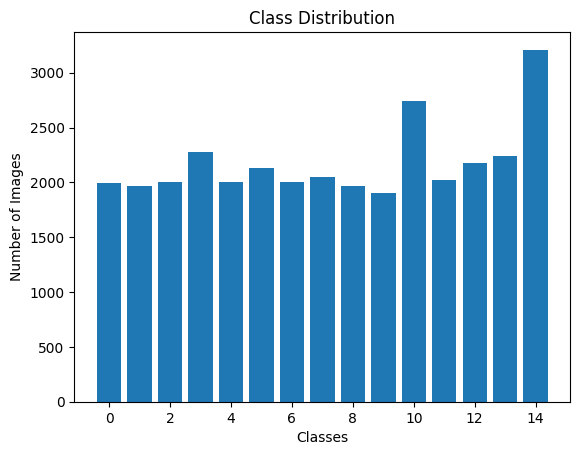

In [8]:
import matplotlib.pyplot as plt

# checking the imabalace
plt.bar(column_data.values(), class_counts.values())
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Class Distribution")
plt.show()


In [9]:
dataDir = tf.keras.preprocessing.image_dataset_from_directory(
    r"C:\Users\YASHASH RAVI\Downloads\plantimages\PlantVillage",
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 32681 files belonging to 15 classes.


In [10]:
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available: 0


In [11]:
# train dataset
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    r"C:\Users\YASHASH RAVI\Downloads\plantimages\PlantVillage",
    validation_split=0.3,   # 30% reserved for val+test
    subset="training",
    seed=123,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
)


val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    r"C:\Users\YASHASH RAVI\Downloads\plantimages\PlantVillage",
    validation_split=0.3,   # same 30% reserved
    subset="validation",
    seed=123,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
)

val_batches = tf.data.experimental.cardinality(val_ds)
test_size = val_batches // 3   # roughly 10% of total dataset

test_ds = val_ds.take(test_size)       # first 10% → test
val_ds = val_ds.skip(test_size)        # remaining 20% → validation



Found 32681 files belonging to 15 classes.
Using 22877 files for training.
Found 32681 files belonging to 15 classes.
Using 9804 files for validation.


In [12]:
class_names = dataDir.class_names
class_names

['Pepper__bell___Bacterial_spot',
 'Pepper__bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites_Two_spotted_spider_mite',
 'Tomato__Target_Spot',
 'Tomato__Tomato_YellowLeaf__Curl_Virus',
 'Tomato__Tomato_mosaic_virus',
 'Tomato_healthy']

In [13]:
# pre proceesing
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.2),
])

resize_rescale = keras.Sequential([
    keras.layers.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    keras.layers.Rescaling(1./255),
])

In [14]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = keras.models.Sequential([
    resize_rescale,
    data_augmentation,
    keras.layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=input_shape),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(len(column_name), activation='softmax'),
])

model.build(input_shape=input_shape)

e:\python\tenserflow\practise\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (120, 256, 256, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (120, 256, 256, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (120, 254, 254, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (120, 127, 127, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (120, 125, 125, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (120, 62, 62, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (120, 60, 60, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (120, 30, 30, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (120, 28, 28, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (120, 14, 14, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (120, 12, 12, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (120, 6, 6, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (120, 4, 4, 64)        │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (120, 2, 2, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (120, 256)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (120, 64)              │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (120, 15)              │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 184,527 (720.81 KB)

 Trainable params: 184,527 (720.81 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# model.build(input_shape=(BATCH_SIZE,IMAGE_SIZE,IMAGE_SIZE,CHANNELS))

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [17]:
# from tensorflow.keras.callbacks import EarlyStopping

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

model.fit(train_ds,
          validation_data=val_ds,
          batch_size=80,
          epochs=30,
          callbacks=[early_stop]
          )


Epoch 1/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 528s 3s/step - accuracy: 0.2654 - loss: 2.1823 - val_accuracy: 0.3166 - val_loss: 2.0972
Epoch 2/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 560s 3s/step - accuracy: 0.5182 - loss: 1.4275 - val_accuracy: 0.5561 - val_loss: 1.3900
Epoch 3/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 498s 3s/step - accuracy: 0.6627 - loss: 0.9891 - val_accuracy: 0.6295 - val_loss: 1.1621
Epoch 4/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 501s 3s/step - accuracy: 0.7502 - loss: 0.7352 - val_accuracy: 0.5833 - val_loss: 1.4529
Epoch 5/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 488s 3s/step - accuracy: 0.7819 - loss: 0.6294 - val_accuracy: 0.7003 - val_loss: 0.9851
Epoch 6/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 479s 3s/step - accuracy: 0.8214 - loss: 0.5177 - val_accuracy: 0.8147 - val_loss: 0.5578
Epoch 7/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 602s 3s/step - accuracy: 0.8363 - loss: 0.4709 - val_accuracy: 0.8103 - val_loss: 0.5758
Epoch 8/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 646s 3s/step - accuracy: 0.8622 - loss: 0.3992 - val_accu

In [18]:
model.save(r"E:\python\tenserflow\Exercises\potato_healthy_plant_detection\model_healty_plant\plant_status_detector_v3.1.keras")

In [19]:
model.evaluate(test_ds)

27/27 ━━━━━━━━━━━━━━━━━━━━ 18s 665ms/step - accuracy: 0.9389 - loss: 0.1797


[0.17968210577964783, 0.9388889074325562]

In [21]:
model_load = keras.models.load_model(r"E:\python\tenserflow\Exercises\potato_healthy_plant_detection\model_healty_plant\plant_status_detector_v3.1.keras")

In [32]:
import cv2
def model_predict(image_path):
    img_input_2 = cv2.imread(str(image_path))

    input_img_21 = tf.keras.preprocessing.image.img_to_array(img_input_2)
    input_img_21_array = tf.expand_dims(input_img_21, 0)

    prediction = model_load.predict(input_img_21_array)
    prediction

    pred_val = column_name[np.argmax(prediction)]

    confidence = round(100 * (np.max(prediction[0])))

    plt.imshow(cv2.cvtColor(img_input_2, cv2.COLOR_BGR2RGB))  # show original image
    plt.axis("off")
    plt.title(f"{pred_val} ({confidence}%)")
    plt.show()

    print(pred_val)
    print(confidence)

    return pred_val, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


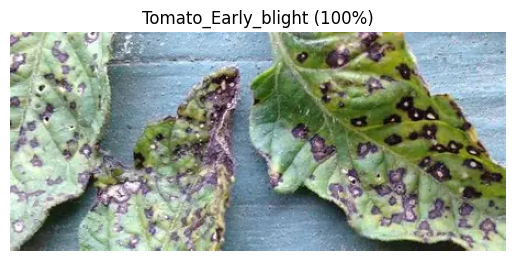

Tomato_Early_blight
100


('Tomato_Early_blight', 100)

In [40]:
model_predict(r"C:\Users\YASHASH RAVI\Downloads\OIP (1).webp")